# C3 DistilBERT — thiết kế của Nhật Huy, chạy trên RTX 5060
Ba lượt full seed 42, 123, 2026 đã được train từ pretrained ngày 21/10/2026 trên máy
RTX 5060 của Duy. Đây là bộ C3 dùng trong báo cáo 2.1, thay bộ C3 lịch sử trong bảng chính.
Không gộp thêm kết quả RTX 3050 thành sáu seed. Run All kiểm artifact và suy luận lại
validation/test từ checkpoint đã có; code và lệnh train được trình bày riêng.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/current_report.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.current_report import current_c3_root, verify_current_report, checked_c3, replay_current_c3
from src.notebook_support import artifacts_root
from src.datasets.goemotions import multi_hot, sha256, REVISION
from src.evaluation.protocols import read_json
from src.evaluation.metrics import evaluate_multilabel
from src.models.transformer import METRIC_NAMES
from scripts.analysis.summarize_project import summarize
C3_RUN, ARTIFACTS = current_c3_root(), artifacts_root()
verified, frames, names = verify_current_report(str(ARTIFACTS), str(C3_RUN))
snapshot = verified['report_snapshot']
completion = read_json(C3_RUN/'completion.json')
torch.set_num_threads(4)
print('Python:', sys.version.split()[0], '| torch:', torch.__version__)
print('Thiết bị replay:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Revision dữ liệu:', REVISION)

PASS A: 12 dòng từ scores thật


PASS B: 6 dòng từ scores thật


PASS C: bert seed 42


PASS C: bert seed 123


PASS C: bert seed 2026


...

PASS C: roberta seed 2026


PASS C: distilbert seed 42


PASS C: distilbert seed 123


PASS C: distilbert seed 2026


Python: 3.13.9 | torch: 2.13.0+cu130
Thiết bị replay: NVIDIA GeForce RTX 5060 Laptop GPU
Revision dữ liệu: add492243ff905527e67aeb8b80c082af02207c3


## 1. Thiết lập đã khóa trước khi train
Official split: 43.410 train / 5.426 validation / 5.427 test; 28 nhãn.
Checkpoint chọn theo Macro-F1 validation @0,5; ngưỡng riêng cũng chỉ chọn trên validation.
Muốn train bộ mới, dùng `python -m scripts.distilbert.reproduce_c3 --output reports/c3_new_run`.
Đường dẫn mới giúp giữ nguyên checkpoint và kết quả của báo cáo đã nộp.

In [2]:
plan = read_json(C3_RUN/'training_plan.json')['plan']
assert plan['config'] == read_json(ROOT/'configs/distilbert_full.json')
assert plan['seeds'] == [42,123,2026] and not plan['test_used_for_selection']
display(pd.Series(plan['config']))
display(pd.DataFrame([dict(split=s, rows=len(df), unique_ids=df.id.nunique()) for s,df in frames.items()]))
display(pd.Series(completion['environment']))

mode                                                               full
model_id                             distilbert/distilbert-base-uncased
revision                       12040accade4e8a0f71eabdb258fecc2e7e948be
seed                                                                 42
subset_seed                                                        2026
train_limit                                                        None
validation_limit                                                   None
epochs                                                                3
max_length                                                          128
batch_size                                                           16
gradient_accumulation_steps                                           1
eval_batch_size                                                      16
learning_rate                                                   0.00002
weight_decay                                                    

,split,rows,unique_ids
0,train,43410,43410
1,validation,5426,5426
2,test,5427,5427


python                                                   3.13.9
packages      {'torch': '2.13.0+cu130', 'transformers': '4.5...
device                                                     cuda
gpu                          NVIDIA GeForce RTX 5060 Laptop GPU
cuda_build                                                 13.0
dtype: object

## 2. Kiểm checkpoint, hash và protocol của đủ ba seed

In [3]:
receipts, runs = [], {}
for seed in (42,123,2026):
    meta, protocol = checked_c3(C3_RUN, seed)
    runs[seed] = meta
    assert meta['n_train'] == 43410 and meta['n_validation'] == 5426 and not meta['test_used']
    receipts.append(dict(seed=seed, best_epoch=meta['best_epoch'], gpu=meta['environment']['gpu'],
        n_train=meta['n_train'], n_validation=meta['n_validation'],
        model_sha256=meta['artifact_sha256']['best/model.safetensors'],
        checkpoint_selection='validation Macro-F1 @0.5'))
display(pd.DataFrame(receipts))
print('PASS: cả ba bundle mới có thật, đủ hash; không thay bằng checkpoint RTX 3050.')

,seed,best_epoch,gpu,n_train,n_validation,model_sha256,checkpoint_selection
0,42,3,NVIDIA GeForce RTX 5060 Laptop GPU,43410,5426,e4458dc5e419102e1f4d4d275e95827ee684d5841a57a1...,validation Macro-F1 @0.5
1,123,3,NVIDIA GeForce RTX 5060 Laptop GPU,43410,5426,7c189295f9e40228914692e9371e776466dcddf2dfe295...,validation Macro-F1 @0.5
2,2026,3,NVIDIA GeForce RTX 5060 Laptop GPU,43410,5426,8726f8cb78632f57132e5754ed52b26787f7c820d244d3...,validation Macro-F1 @0.5


PASS: cả ba bundle mới có thật, đủ hash; không thay bằng checkpoint RTX 3050.


## 3. Loss và Macro-F1 validation qua ba epoch đã chạy

,architecture,seed,epoch,train_loss,validation_macro_f1,validation_micro_f1,epoch_train_and_eval_seconds
0,distilbert,42,1,0.163028,0.262594,0.510206,213.612622
1,distilbert,42,2,0.085855,0.370963,0.557371,167.680795
2,distilbert,42,3,0.075992,0.401590,0.567226,170.348879
3,distilbert,123,1,0.162730,0.267330,0.513030,252.838897
4,distilbert,123,2,0.086128,0.382593,0.565639,280.185918
5,distilbert,123,3,0.076082,0.411718,0.574579,276.941088
6,distilbert,2026,1,0.162095,0.254358,0.518967,296.754467
7,distilbert,2026,2,0.086049,0.383284,0.563486,258.699377
8,distilbert,2026,3,0.075809,0.404701,0.571964,273.293614


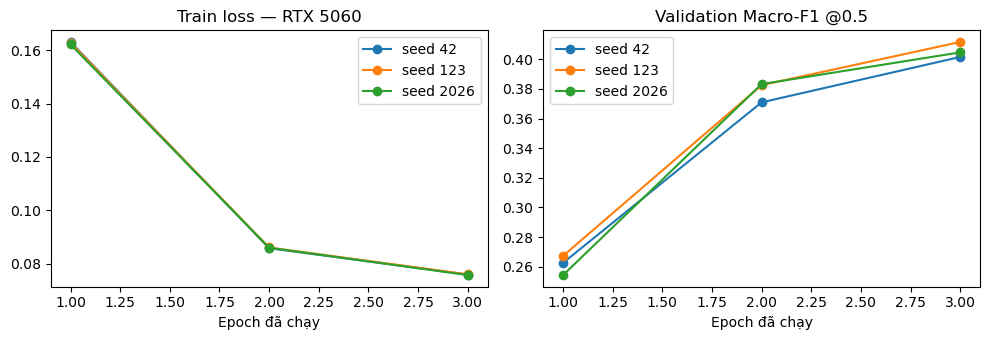

Ba seed chọn epoch 3; chưa có đối chứng cho kết luận đã hội tụ hoặc tối ưu siêu tham số.


In [4]:
import matplotlib.pyplot as plt
history = pd.read_csv(C3_RUN/'history.csv')
display(history)
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for seed, group in history.groupby('seed'):
    axes[0].plot(group.epoch, group.train_loss, marker='o', label=f'seed {seed}')
    axes[1].plot(group.epoch, group.validation_macro_f1, marker='o', label=f'seed {seed}')
axes[0].set_title('Train loss — RTX 5060'); axes[1].set_title('Validation Macro-F1 @0.5')
for ax in axes: ax.set_xlabel('Epoch đã chạy'); ax.legend()
plt.tight_layout(); plt.show(); plt.close()
print('Ba seed chọn epoch 3; chưa có đối chứng cho kết luận đã hội tụ hoặc tối ưu siêu tham số.')

## 4. Vòng lặp train và số cập nhật thực tế
Cell hiển thị implementation đã tạo bộ C3 này. FP16 có thể bỏ một bước khi gradient
không hữu hạn; vì vậy số bước optimizer thực tế được đối chiếu riêng với số dự kiến.

In [5]:
import inspect
from IPython.display import Code
from scripts.distilbert import train_distilbert
display(Code(inspect.getsource(train_distilbert.main), language='python'))
steps = []
for seed, meta in runs.items():
    assert meta['optimizer_steps'] + len(meta['skipped_amp_steps']) == meta['planned_optimizer_steps']
    steps.append(dict(seed=seed, optimizer_updates=meta['optimizer_steps'],
        planned_updates=meta['planned_optimizer_steps'], skipped_amp_updates=len(meta['skipped_amp_steps']),
        training_seconds=meta['fit_and_validation_seconds']))
display(pd.DataFrame(steps))

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--config", default="configs/distilbert_pilot.json")
    parser.add_argument("--seed", type=int)
    parser.add_argument("--output", help="New output directory; existing run never overwritten")
    args = parser.parse_args()
    config = read_json(args.config)
    if args.seed is not None:
        config["seed"] = args.seed
    output = args.output or ROOT / "data/processed/c3_distilbert" / config["mode"] / f"seed_{config['seed']}"
    run_training(config, output)

,seed,optimizer_updates,planned_updates,skipped_amp_updates,training_seconds
0,42,8141,8142,1,554.069725
1,123,8141,8142,1,812.411995
2,2026,8141,8142,1,831.862541


## 5. Suy luận mới toàn bộ validation và test
Nạp lại từng checkpoint đã khóa, chạy model thật rồi đối chiếu scores/metric với
artifact báo cáo. Không tìm lại ngưỡng; cell dừng nếu scores hoặc metric không khớp.

In [6]:
fresh_parts = []
for seed in (42,123,2026):
    for split in ('validation','test'):
        fresh_parts.append(replay_current_c3(C3_RUN, seed, frames, names, split))
        print('PASS real inference:', seed, split, len(frames[split]))
fresh = pd.concat(fresh_parts, ignore_index=True)
assert len(fresh) == 18
display(fresh)

PASS real inference: 42 validation 5426


PASS real inference: 42 test 5427


PASS real inference: 123 validation 5426


PASS real inference: 123 test 5427


PASS real inference: 2026 validation 5426


PASS real inference: 2026 test 5427


,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss,score_max_abs_diff,metric_max_abs_diff,device
0,C_distilbert,42,validation,fixed,5426,0.401590,0.567226,0.574425,0.342113,0.705101,0.474451,0.030403,0.0,0.0,cuda
1,C_distilbert,42,validation,global,5426,0.473077,0.594963,0.499156,0.521880,0.526895,0.683229,0.039065,0.0,0.0,cuda
2,C_distilbert,42,validation,tuned,5426,0.503101,0.600565,0.522756,0.522399,0.546213,0.666928,0.037254,0.0,0.0,cuda
3,C_distilbert,42,test,fixed,5427,0.411260,0.573668,0.590028,0.353195,0.713078,0.479855,0.029706,0.0,0.0,cuda
4,C_distilbert,42,test,global,5427,0.463205,0.594668,0.435707,0.523133,0.520062,0.694264,0.039419,0.0,0.0,cuda
5,C_distilbert,42,test,tuned,5427,0.483342,0.590328,0.499498,0.512741,0.531721,0.663454,0.038353,0.0,0.0,cuda
6,C_distilbert,123,validation,fixed,5426,0.411718,0.574579,0.582151,0.349682,0.711574,0.481818,0.029962,0.0,0.0,cuda
7,C_distilbert,123,validation,global,5426,0.482905,0.584089,0.470021,0.572549,0.488010,0.727273,0.043494,0.0,0.0,cuda
8,C_distilbert,123,validation,tuned,5426,0.506407,0.606525,0.521014,0.532394,0.549987,0.676019,0.036833,0.0,0.0,cuda
9,C_distilbert,123,test,fixed,5427,0.415356,0.574726,0.594073,0.355752,0.716003,0.480013,0.029588,0.0,0.0,cuda


## 6. Mean và sample std của đủ ba seed — đối chiếu báo cáo 2.1

In [7]:
averages = summarize(fresh.to_dict('records'))
for row in averages:
    expected = next(r for r in snapshot['mean_std'] if r['system'] == 'C_distilbert'
                    and r['split'] == row['split'] and r['threshold_mode'] == row['threshold_mode'])
    for metric in METRIC_NAMES:
        for suffix in ('_mean','_std'):
            assert abs(row[metric+suffix] - expected[metric+suffix]) <= 1e-12
display(pd.DataFrame(averages)[['split','threshold_mode','n_runs','macro_f1_mean','macro_f1_std',
                              'micro_f1_mean','micro_f1_std','hamming_loss_mean']])
print('PASS: sáu nhóm mean ± sample std (ddof=1) khớp bộ số báo cáo 2.1.')

,split,threshold_mode,n_runs,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,hamming_loss_mean
0,validation,fixed,3,0.406003,0.005188,0.571257,0.003728,0.030137
1,validation,global,3,0.475391,0.006665,0.586333,0.007756,0.042235
2,validation,tuned,3,0.507436,0.004931,0.603758,0.003003,0.036695
3,test,fixed,3,0.413449,0.002063,0.574208,0.000529,0.029666
4,test,global,3,0.464791,0.004662,0.583668,0.009609,0.042841
5,test,tuned,3,0.486302,0.006508,0.595227,0.004605,0.037583


PASS: sáu nhóm mean ± sample std (ddof=1) khớp bộ số báo cáo 2.1.


## 7. Ngưỡng và năm nhãn hiếm
Nhãn hiếm chọn theo support trên train. Điểm validation sau chọn ngưỡng có thể lạc quan;
bảng test dưới được tính lại từ scores mới, không dùng test thay ngưỡng.

In [8]:
from src.models.baseline import load_aligned_scores
support = multi_hot(frames['train'].labels.tolist()).sum(axis=0)
rare_ids = np.argsort(support)[:5].tolist()
threshold_rows, rare_rows = [], []
for seed in (42,123,2026):
    _, protocol = checked_c3(C3_RUN, seed)
    scores = load_aligned_scores(ROOT/f'reports/notebook_replay/C_distilbert_{seed}_test.npz', frames['test'].id, names)
    truth = multi_hot(frames['test'].labels.tolist())
    for choice in protocol['configurations']:
        metric = evaluate_multilabel(truth, scores, names, choice['thresholds'])
        rare_rows.extend(dict(seed=seed, mode=choice['threshold_mode'], **metric['per_label'][j]) for j in rare_ids)
        if choice['threshold_mode'] == 'tuned':
            threshold_rows.extend(dict(seed=seed,label=label,threshold=value) for label,value in zip(names,choice['thresholds']))
display(pd.DataFrame(threshold_rows).pivot(index='label',columns='seed',values='threshold').reindex(names))
display(pd.DataFrame(rare_rows).groupby(['label','mode']).f1.agg(['mean','std']))

seed,42,123,2026
label,,,
admiration,0.40,0.30,0.40
amusement,0.30,0.40,0.35
anger,0.35,0.25,0.25
annoyance,0.15,0.20,0.20
approval,0.15,0.20,0.20
caring,0.20,0.20,0.15
confusion,0.25,0.25,0.25
curiosity,0.15,0.15,0.30
desire,0.30,0.25,0.35


mean       std
label         mode                      
embarrassment fixed   0.157871  0.064415
              global  0.472810  0.024928
              tuned   0.360829  0.055062
grief         fixed   0.000000  0.000000
              global  0.000000  0.000000
              tuned   0.000000  0.000000
nervousness   fixed   0.000000  0.000000
              global  0.244572  0.129652
              tuned   0.322786  0.107272
pride         fixed   0.000000  0.000000
              global  0.074074  0.128300
              tuned   0.452412  0.070418
relief        fixed   0.000000  0.000000
              global  0.000000  0.000000
              tuned   0.043011  0.074497

## 8. Phân tích lỗi và các ví dụ trong báo cáo — kiểm bằng scores vừa suy luận

In [9]:
from scripts.analysis.analyze_project_errors import analyze_arrays
representative = snapshot['representatives']['distilbert']
seed = representative['seed']
scores = load_aligned_scores(ROOT/f'reports/notebook_replay/C_distilbert_{seed}_test.npz', frames['test'].id, names)
counts, pairs, _, _ = analyze_arrays(frames['test'], names, rare_ids, support,
    {'distilbert':representative}, {'distilbert':scores}, {'distilbert':0.5})
for row in counts:
    expected = next(r for r in snapshot['error_counts'] if r['architecture']=='distilbert' and r['category']==row['category'])
    assert row == expected
display(pd.DataFrame(counts))
examples = []
for example in (e for e in snapshot['report_examples'] if e['architecture']=='distilbert'):
    index = int(np.flatnonzero(frames['test'].id.to_numpy()==example['id'])[0])
    predicted = [names[j] for j in np.flatnonzero(scores[index]>=0.5)]
    assert predicted == example['predicted_labels'] and frames['test'].text.iloc[index] == example['text']
    examples.append({k:v for k,v in example.items() if k!='scores'})
display(pd.DataFrame(examples))
print('PASS: ba nhóm lỗi và ba ví dụ C3 khớp nội dung báo cáo.')

,architecture,seed,category,error_samples,total_samples,eligible_samples,fraction_all_samples,fraction_eligible
0,distilbert,123,partial_multi_label,447,5427,837,0.082366,0.534050
1,distilbert,123,rare_false_negative,90,5427,93,0.016584,0.967742
2,distilbert,123,missed_extra_pair,1139,5427,5427,0.209877,0.209877


,id,text,architecture,seed,true_labels,predicted_labels,missed_labels,extra_labels
0,eczj48j,This!!! 🐃 and 💍 for your hard work!,distilbert,123,"[admiration, excitement, neutral]",[admiration],"[excitement, neutral]",[]
1,ed0jr9i,Try nonchalantly handing them your card as if ...,distilbert,123,[embarrassment],[],[embarrassment],[]
2,eczcvgx,"I always plan that, my wife usually has other ...",distilbert,123,[neutral],[approval],[neutral],[approval]


PASS: ba nhóm lỗi và ba ví dụ C3 khớp nội dung báo cáo.


## 9. Thử dự đoán C3 và xác nhận mô hình demo cuối
Hàm dưới thực sự nạp C3 seed đại diện và trả 28 điểm cho câu nhập.
Demo Gradio chính của nhóm vẫn dùng BERT seed 123, chọn bằng validation; bảng này
chỉ minh họa checkpoint C3 vừa được kiểm, không đổi mô hình demo theo điểm test.

In [10]:
from src.models.distilbert_study import load_bundle, predict_texts
device = 'cuda' if torch.cuda.is_available() else 'cpu'
bundle = load_bundle(C3_RUN/f'seed_{seed}', device)
predictions = predict_texts(bundle, ['Thank you, I am so happy!', 'Why did this happen?'])
display(pd.DataFrame([{k:v for k,v in item.items() if k!='scores'} for item in predictions]))
display(pd.DataFrame([item['scores'] for item in predictions]).T)
assert all(len(item['scores']) == 28 for item in predictions)
del bundle
if device == 'cuda': torch.cuda.empty_cache()
print('Demo chính:', verified['selection']['architecture'], 'seed', verified['selection']['seed'])
print('Hoàn tất: 3 checkpoint C3 mới, 6 lượt suy luận full, 18 dòng metric; không train thêm trong Run All.')

,text,labels,original_tokens,truncated,max_length
0,"Thank you, I am so happy!",[gratitude],10,False,128
1,Why did this happen?,[],7,False,128


,0,1
admiration,0.033821,0.000966
amusement,0.011916,0.000914
anger,0.001515,0.004977
annoyance,0.001736,0.018065
approval,0.009498,0.002536
caring,0.010501,0.001323
confusion,0.002048,0.205042
curiosity,0.001876,0.489951
desire,0.003172,0.000561
disappointment,0.001404,0.003486


Demo chính: bert seed 123
Hoàn tất: 3 checkpoint C3 mới, 6 lượt suy luận full, 18 dòng metric; không train thêm trong Run All.
